In [6]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import copy
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from PIL import Image  # Import PIL to resize images

In [7]:
# Data augmentation and normalization for training
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [8]:
# Define the local data path
data_dir = r"C:\Users\adria\Desktop\Msx Project\Coding\1st dataset\Filtered Dataset"  # Replace this with your local path

# Load data
Datasets = {x: datasets.ImageFolder(
                os.path.join(data_dir, x),
                data_transforms[x]
            ) for x in ['train', 'test']}

# Define Train and Validation Dataloaders
dataloaders = {x: torch.utils.data.DataLoader(
                   Datasets[x], batch_size=5,
                   shuffle=True, num_workers=0
               ) for x in ['train', 'test']}

dataset_sizes = {x: len(Datasets[x]) for x in ['train', 'test']}
print(dataset_sizes)

class_names = Datasets['train'].classes
print(class_names)

{'train': 485, 'test': 121}
['PASS', 'REJECT']


In [9]:
# Initialize counters for train and test sets
train_label_counts = {class_name: 0 for class_name in class_names}
test_label_counts = {class_name: 0 for class_name in class_names}

# Iterate through the train dataset to count labels
for inputs, labels in dataloaders['train']:
    for label in labels.tolist():
        class_name = class_names[label]
        train_label_counts[class_name] += 1

# Iterate through the test dataset to count labels
for inputs, labels in dataloaders['test']:
    for label in labels.tolist():
        class_name = class_names[label]
        test_label_counts[class_name] += 1

# Print the label counts for train and test sets
print("Train Label Counts:")
for class_name, count in train_label_counts.items():
    print(f"{class_name}: {count}")

print("\nTest Label Counts:")
for class_name, count in test_label_counts.items():
    print(f"{class_name}: {count}")

Train Label Counts:
PASS: 245
REJECT: 240

Test Label Counts:
PASS: 61
REJECT: 60


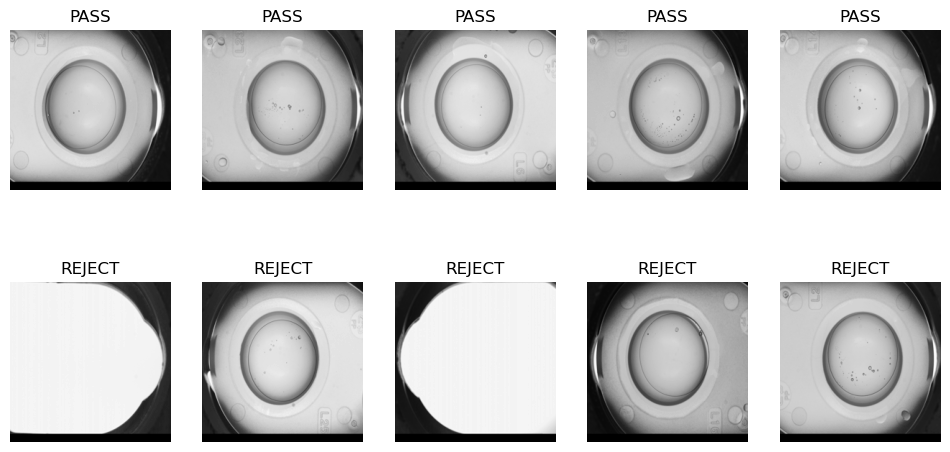

In [10]:
train_path = r"C:\Users\adria\Desktop\Msx Project\Coding\1st dataset\Filtered Dataset\Train"
test_path = r"C:\Users\adria\Desktop\Msx Project\Coding\1st dataset\Filtered Dataset\Test"

pass_images = [img for img in os.listdir(f'{train_path}/PASS')]
reject_images = [img for img in os.listdir(f'{train_path}/REJECT')]

# Randomly select a few images from the set to view
pass_select = np.random.choice(pass_images, 5, replace=False)
reject_select = np.random.choice(reject_images, 5, replace=False)

# Define a common size for all images
common_size = (224, 224)

# Plot the selected images with equal sizes
fig = plt.figure(figsize=(12, 6))


for i in range(10):
    if i < 5:
        fpath = f'{train_path}/PASS/{pass_select[i]}'
        label = 'PASS'
    else:
        fpath = f'{train_path}/REJECT/{reject_select[i-5]}'
        label = 'REJECT'
    ax = fig.add_subplot(2, 5, i+1)
    
    # Open the image using PIL and resize it to the common size
    im = Image.open(fpath)
    im = im.resize(common_size)
    
    plt.imshow(im, cmap='gray')
    plt.title(label)
    plt.axis('off')

plt.show()


In [11]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [12]:
import time
import copy

In [13]:
def train_model_with_early_stopping(model, lossFunction, optimizer, scheduler, num_epochs=100, patience=50):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    consecutive_epochs_without_improvement = 0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = lossFunction(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(
                phase, epoch_loss, epoch_acc))

            # Early stopping: Check if validation loss improved
            if phase == 'test':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    consecutive_epochs_without_improvement = 0
                else:
                    consecutive_epochs_without_improvement += 1

        # Check if early stopping criteria are met
        if consecutive_epochs_without_improvement >= patience:
            print(f"Early stopping after {epoch} epochs")
            break

        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:.4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

# Usage
#best_model = train_model_with_early_stopping(model, Loss_Function, optimizer, Decay_Learning_Rate, num_epochs=100, patience=2)

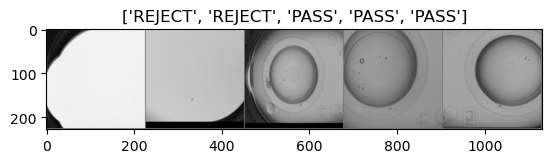

In [14]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated

# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

In [15]:
def visualize_model(model, num_images=15):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['test']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            percentage = torch.sigmoid(outputs)[0] * 100 
            _, indices = torch.sort(outputs, descending=True)
            probs=[percentage[idx].item() for idx in indices[0][:4]]

            classes=[class_names[idx] for idx in indices[0][:4]]

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 5, images_so_far)
                ax.axis('off')
                ax.set_title('predicted: {}'.format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

In [16]:
import torchvision
from torchvision import models
import torch.nn as nn

In [17]:
#Transfer Learning by fineTuning the pretrained Resnet101 Model
#Load Resnet101 pretained Model
#Resnet101 = models.resnet101(pretrained=True)
#If pretained is not working, you can also use weights instead.
Resnet101 = models.resnet101(weights=True)

print(Resnet101)
#Set the resnet param.requires_grad = True to calculate the gradient,
#so that model fine-tunes the weights of the pretrained network
#by continuing the backpropagation.
for param in Resnet101.parameters():
    param.requires_grad = True

#Get the number of Input features of Resnet last fully connected layer
#because we are going to replace it with new fully connected layer.
in_features = Resnet101.fc.in_features

#Reset the final fully connected layer of the of the pre-trained Resnet.
Resnet101.fc = nn.Linear(in_features, len(class_names))

Resnet_fineTuning = Resnet101.to(device)

c:\Users\adria\.conda\envs\deeplearning\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [18]:
import torch.optim as optim
from torch.optim import lr_scheduler

In [19]:
#Define optimzation algorithm
optimizer = optim.Adam(Resnet_fineTuning.parameters(), lr=0.00001)

# Decay LR by a factor of 0.1 every 7 epochs
Decay_Learning_Rate = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

#Define loss functions
Loss_Function = nn.CrossEntropyLoss()

In [20]:
model_fineTuning = train_model_with_early_stopping(Resnet_fineTuning, Loss_Function, optimizer, Decay_Learning_Rate, num_epochs=25)
torch.save(model_fineTuning, r"C:\Users\adria\Desktop\Msx Project\Coding.pth")

Epoch 0/24
----------
train Loss: 0.5481 Acc: 0.7093
test Loss: 0.6653 Acc: 0.5537

Epoch 1/24
----------
train Loss: 0.4997 Acc: 0.7567
test Loss: 0.6152 Acc: 0.7107

Epoch 2/24
----------
train Loss: 0.4106 Acc: 0.8103
test Loss: 0.5892 Acc: 0.6777

Epoch 3/24
----------
train Loss: 0.4017 Acc: 0.8268
test Loss: 0.5588 Acc: 0.7273

Epoch 4/24
----------
train Loss: 0.4127 Acc: 0.8103
test Loss: 0.5851 Acc: 0.7273

Epoch 5/24
----------
train Loss: 0.3372 Acc: 0.8722
test Loss: 0.5654 Acc: 0.7190

Epoch 6/24
----------
train Loss: 0.3545 Acc: 0.8371
test Loss: 0.7502 Acc: 0.5868

Epoch 7/24
----------
train Loss: 0.3501 Acc: 0.8433
test Loss: 0.5540 Acc: 0.7521

Epoch 8/24
----------
train Loss: 0.3170 Acc: 0.8557
test Loss: 0.5655 Acc: 0.7273

Epoch 9/24
----------
train Loss: 0.3388 Acc: 0.8660
test Loss: 0.5636 Acc: 0.7355

Epoch 10/24
----------
train Loss: 0.3009 Acc: 0.8825
test Loss: 0.6583 Acc: 0.6860

Epoch 11/24
----------
train Loss: 0.3412 Acc: 0.8454
test Loss: 0.5520 Acc